In [35]:
#!pip install botorch
#!pip install pyDOE
#!pip install openpyxl
#!pip install smt
#!pip install scikit-optimize

In [36]:
# Support for math
import numpy as np
import math

# Plotting tools
from matplotlib import pyplot as plt
import matplotlib

import warnings
warnings.filterwarnings('ignore')

#File Tools for local
import pandas as pd

#Sampling
from pyDOE import lhs



In [37]:
import torch
from botorch.models import SingleTaskGP
from botorch.fit import fit_gpytorch_model
from gpytorch.mlls import ExactMarginalLogLikelihood
from botorch.acquisition import qExpectedImprovement
from botorch.optim import optimize_acqf
from botorch.models.deterministic import PosteriorMeanModel
from botorch.acquisition.multi_objective import qExpectedHypervolumeImprovement
from botorch.utils.multi_objective.box_decompositions.non_dominated import FastNondominatedPartitioning

In [71]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)
dtype = torch.float32

bounds = torch.tensor([[0., 0., 0.], [100., 100., 100.]], dtype=dtype, device=device)
refi = torch.tensor([0., 0., 0.], device=device, dtype=dtype)

batch_size=2
iteration_number=12//batch_size

iterations = list(range(1, iteration_number+1))


cpu


#Generate points

In [73]:
from pyDOE import lhs
def latin_hypercube_sum_constraint(n_samples, n_variables, sum_constraint,seed):
    # Step 1: Generate Latin Hypercube Samples
    seed
    lhs_samples = lhs(n_variables, samples=n_samples, criterion='maximin')
    #sampling = LHS(xlimits=xlimits,random_state = np.random.RandomState(0))

    # Step 2: Transform samples to satisfy the sum constraint
    for i in range(n_samples):
        current_sum = np.sum(lhs_samples[i, :])
        lhs_samples[i, :] *= sum_constraint / current_sum

    return lhs_samples

sampled_colors = latin_hypercube_sum_constraint(12, 3, 300,np.random.seed(2))//1
sampled_colors.transpose().shape

(3, 12)

#import data

In [74]:
# Path
xls = pd.read_excel("/Users/clarat/Documents/Sun Lab/Mara_colors/mara_color_data/02_23_Random_Color_Increment.xlsx",sheet_name=["End point","RGB"],engine='openpyxl')

df = xls.get('End point')
df_RGB = xls.get('RGB')

df.head()

,Well\nRow,Well\nCol,Content,Concentration,Raw Data (Abs Spectrum),Raw Data (Abs Spectrum).1,Raw Data (Abs Spectrum).2,Raw Data (Abs Spectrum).3,Raw Data (Abs Spectrum).4,Raw Data (Abs Spectrum).5,...,Raw Data (Abs Spectrum).141,Raw Data (Abs Spectrum).142,Raw Data (Abs Spectrum).143,Raw Data (Abs Spectrum).144,Raw Data (Abs Spectrum).145,Raw Data (Abs Spectrum).146,Raw Data (Abs Spectrum).147,Raw Data (Abs Spectrum).148,Raw Data (Abs Spectrum).149,Raw Data (Abs Spectrum).150
0,NaN,NaN,Wavelength [nm],NaN,400.000,402.000,404.000,406.000,408.000,410.000,...,682.000,684.000,686.000,688.000,690.000,692.000,694.000,696.000,698.000,700.000
1,D,1.0,Sample X37,74626.252,1.363,1.391,1.409,1.438,1.459,1.474,...,0.043,0.042,0.040,0.038,0.035,0.034,0.033,0.031,0.030,0.030
2,D,2.0,Sample X38,25529.573,0.627,0.648,0.663,0.677,0.689,0.694,...,0.066,0.061,0.056,0.051,0.047,0.043,0.041,0.037,0.036,0.035
3,D,3.0,Sample X39,42472.278,0.997,1.023,1.044,1.065,1.080,1.093,...,0.067,0.061,0.057,0.053,0.050,0.047,0.044,0.041,0.040,0.038
4,D,4.0,Sample X40,32500.649,1.461,1.497,1.528,1.560,1.574,1.584,...,0.277,0.267,0.260,0.253,0.247,0.243,0.239,0.236,0.234,0.231


Inputs

In [75]:
vol_mag  = sampled_colors[:,0]
vol_cya = sampled_colors[:,1]
vol_yelo = sampled_colors[:,2]
vol_mag

array([ 82., 165., 105.,  26., 109.,  84.,  32., 214., 114., 139., 214.,
        15.])

Outputs

In [76]:
colors_R = np.array(df_RGB.loc[:,'R/255'])
colors_G = np.array(df_RGB.loc[:,'G/255'])
colors_B = np.array(df_RGB.loc[:,'B/255'])

colors_RGB = list(zip(colors_R,colors_G,colors_B))

colors_RGB

[(0.3254901961, 0.2862745098, 0.07843137255),
 (0.1254901961, 0.1137254902, 0.1960784314),
 (0.137254902, 0.1803921569, 0.1490196078),
 (0.0, 0.3529411765, 0.2117647059),
 (0.003921568627, 0.1176470588, 0.2745098039),
 (0.0, 0.1450980392, 0.2156862745),
 (0.007843137255, 0.2941176471, 0.2666666667),
 (0.2470588235, 0.1098039216, 0.1882352941),
 (0.01176470588, 0.1215686275, 0.3058823529),
 (0.05882352941, 0.09411764706, 0.2549019608),
 (0.2117647059, 0.1176470588, 0.1725490196),
 (0.0, 0.5882352941, 0.07450980392)]

In [77]:
def id_smallest(K,list):
# Smallest K elements indices
# using sorted() + lambda + list slicing
    res = sorted(range(len(list)), key=lambda sub: list[sub])[:K]
    return res


In [78]:
def sum_constraint(n_samples,sum_constraint):
    for i in range(len(n_samples)):
        if sum(n_samples[i]) == 0:
          n_samples[i, :] = sum_constraint/len(n_samples[i])
        current_sum = torch.sum(n_samples[i, :])
        n_samples[i, :] *= sum_constraint / current_sum
    return n_samples

In [79]:
#Setting up the data
volume = torch.tensor(sampled_colors,dtype=dtype) # input
colors = torch.tensor([colors_R,colors_G,colors_B],dtype=dtype).T #output
x = volume
y = colors
# y_eval = multi_objective(y)
# y_eval,  reference_rgb

In [80]:
def closest(lst, K):
     lst = np.asarray(lst)
     idx = (np.abs(lst - K)).argmin()
     return lst[idx]

In [81]:
reference = torch.tensor([0.6275, 0.1255, 0.9412])#[160/255, 32/255, 240/255]
# Modify the objective function to minimize the L2 distance between the predicted and reference RGB values
def multi_objective(predicted_composition,pool_y,pool_x):
    # Reference RGB value (the desired or ideal RGB you want to achieve)
    desired_composition = torch.tensor([0.6275, 0.1255, 0.9412])
    # Calculate the Euclidean distance between measured and desired compositions
    distance = torch.abs(predicted_composition - desired_composition).mean(axis=1).sort()[1]
    predicted_composition = predicted_composition[distance]
    pool_distance = torch.sqrt(torch.sum((pool_y.unsqueeze(1) - predicted_composition) ** 2, dim=2))

    id_match = torch.argmin(pool_distance, dim=0)
    #d_pool =  torch.abs(pool_y - predicted_composition).mean(axis=1)
    #actual = actual_pool[distance]
    #candidate = actual_candidates[distance]
    return pool_y[id_match],pool_x[id_match]

In [82]:
cand = torch.randn(5, 3)

cand
multi_objective(cand,y,x)


(tensor([[0.3255, 0.2863, 0.0784],
         [0.0000, 0.5882, 0.0745],
         [0.0588, 0.0941, 0.2549],
         [0.0000, 0.5882, 0.0745],
         [0.0000, 0.5882, 0.0745]]),
 tensor([[ 82.,  39., 177.],
         [ 15.,  69., 214.],
         [139., 100.,  59.],
         [ 15.,  69., 214.],
         [ 15.,  69., 214.]]))

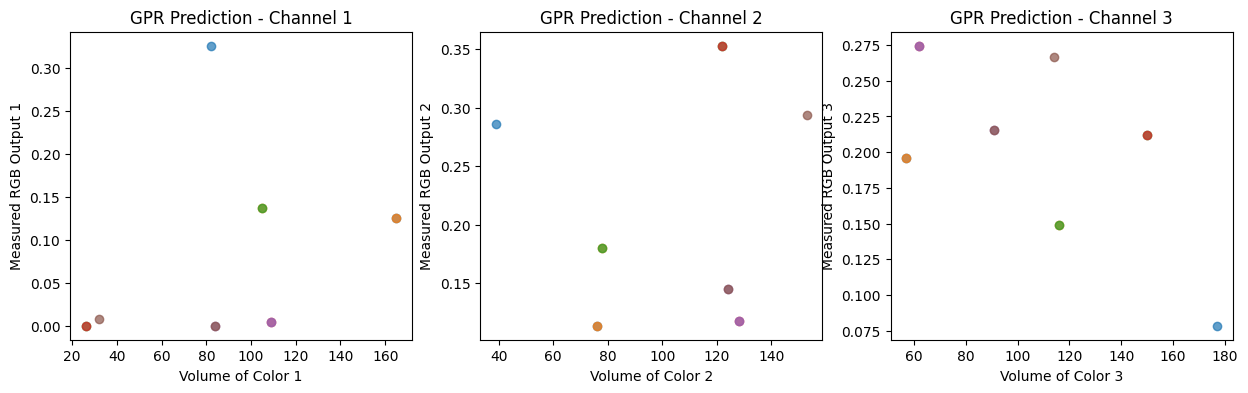

In [83]:
# Plot the results for each RGB channel in separate 2D plots
plt.figure(figsize=(15, 4))
for i in range(3):
    for j in range(len(y)//batch_size):
        # Plot training data
        plt.subplot(1,3,i+1)
        plt.scatter(x[j:j+batch_size, i], y[j:j+batch_size,i], label='Training Data', alpha=0.7)

        plt.title(f'GPR Prediction - Channel {i+1}')
        plt.xlabel(f'Volume of Color {i+1}')
        plt.ylabel(f'Measured RGB Output {i+1}')
#plt.legend()


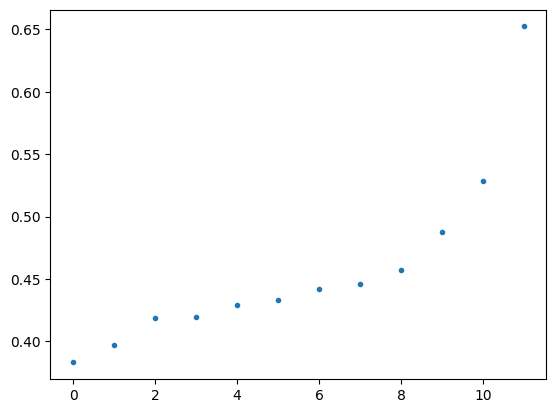

In [84]:
plt.plot(abs(y-reference).mean(axis = 1).sort()[0],'.')

#BO

Reference: https://gist.github.com/danhphan/af53fb7958a28c2e2d514221ea83bd9c

In [85]:
i = 0
train_x = torch.tensor(x[i:i+batch_size], dtype=torch.float32).squeeze(0).to(device=device, dtype=dtype).reshape(batch_size,3)
train_y = torch.tensor(y[i:i+batch_size], dtype=torch.float32)

train_x.shape, train_y.shape

(torch.Size([2, 3]), torch.Size([2, 3]))

In [86]:
test_model = SingleTaskGP(train_x, train_y).to(device=device, dtype=dtype)
mll = ExactMarginalLogLikelihood(test_model.likelihood, test_model)
fit_gpytorch_model(mll)

with torch.no_grad():
    posterior = test_model.posterior(train_x)
    mean = posterior.mean
    variance = posterior.variance
mean

tensor([[0.3157, 0.2779, 0.0841],
        [0.1352, 0.1221, 0.1904]])

#Bayesian Optimization

https://distill.pub/2020/bayesian-optimization/

https://github.com/pytorch/botorch/issues/546

In [87]:
#acquisition function
frames_x = [train_x.cpu().numpy()]
frames_y = [train_y.cpu().numpy()]
best_points = []
best_y_values=[]
means = []
variances =[]

gp_model = SingleTaskGP(train_x, train_y).to(device=device, dtype=dtype)
mll = ExactMarginalLogLikelihood(gp_model.likelihood, gp_model)
fit_gpytorch_model(mll)

#condition for the pareto front
partitioning = FastNondominatedPartitioning(
    ref_point=refi,
    Y=train_y,
    )

def prediction(cand_eval):
    with torch.no_grad():
        posterior = gp_model.posterior(cand_eval)
        mean = posterior.mean
        variance = posterior.variance
        return mean,variance


for iteration in  range(iteration_number):
    print("Iteration: "+str(iteration))
    EI = qExpectedHypervolumeImprovement(
        model=gp_model,
        ref_point=refi,
        partitioning=partitioning,
        #sampler=qehvi_sampler,
    )
    #optimisation of acquisition function
    candidate, _ = optimize_acqf(
        acq_function=EI,
        bounds=bounds,
        q=batch_size,
        num_restarts=5,
        raw_samples=512,
        options={"dtype": dtype, "device": device}
    )
    
    pred_y = multi_objective(prediction(candidate)[0],train_y,train_x)#torch.tensor(objective(candidate), dtype=torch.float32).reshape(len(objective(candidate)),1)
    new_y = pred_y[0]
    new_x = pred_y[1]
    train_x = torch.cat([train_x, new_x]) 
    train_y = torch.cat([train_y, new_y])

    gp_model = SingleTaskGP(train_x, train_y).to(device=device, dtype=dtype)
    mll = ExactMarginalLogLikelihood(gp_model.likelihood, gp_model)
    fit_gpytorch_model(mll)
    #condition for the pareto front
    partitioning = FastNondominatedPartitioning(ref_point=refi,Y=train_y)

    means.append(prediction(candidate)[0].cpu().numpy())
    variances.append(prediction(candidate)[1].cpu().numpy())
    frames_x.append(candidate.cpu().numpy())
    frames_y.append(new_y.cpu().detach().numpy())
    best_points.append(train_x[new_x.argmin(), :].cpu().numpy())
    best_y_values.append([train_y[:,0][train_y[:,0].argmin()].cpu().detach().numpy(),train_y[:,1][train_y[:,1].argmin()].cpu().detach().numpy(),train_y[:,2][train_y[:,2].argmin()].cpu().detach().numpy()])

#best_point = train_x[train_y.argmin(), :]
#best_value = train_y.min().item()

best_y_values = np.array([element for element in best_y_values])



Iteration: 0
Iteration: 1
Iteration: 2
Iteration: 3
Iteration: 4
Iteration: 5


In [88]:
train_x

tensor([[ 82.,  39., 177.],
        [165.,  76.,  57.],
        [165.,  76.,  57.],
        [165.,  76.,  57.],
        [165.,  76.,  57.],
        [165.,  76.,  57.],
        [165.,  76.,  57.],
        [165.,  76.,  57.],
        [ 82.,  39., 177.],
        [ 82.,  39., 177.],
        [ 82.,  39., 177.],
        [ 82.,  39., 177.],
        [ 82.,  39., 177.],
        [ 82.,  39., 177.]])

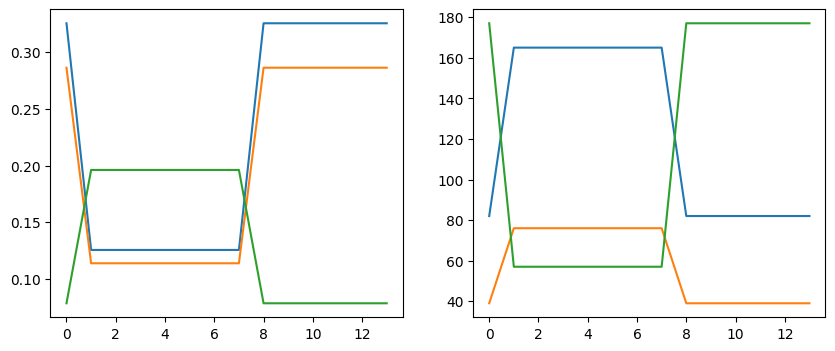

In [89]:
#abs(means[0]-y.numpy()).mean(axis=1).argsort()
plt.figure(figsize=(10, 4))
plt.subplot(1,2,1)
plt.plot(train_y)
plt.subplot(1,2,2)
plt.plot(train_x)

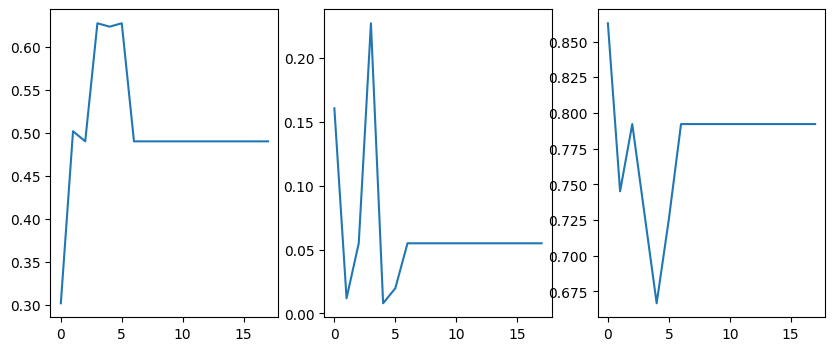

In [54]:
#plt.plot(train_x,train_y,'.')
distance = abs(train_y-reference)
plt.figure(figsize=(10, 4))
for i in range(3):
    plt.subplot(1,3,i+1)
    plt.plot(distance[:,i])


In [55]:
#print("Best observed point:", sum_constraint(best_point.reshape(1,3),300).cpu().numpy(), "Best observed value:", best_value)
#best_y_values

In [56]:
x_vol = sum_constraint(train_x,300)


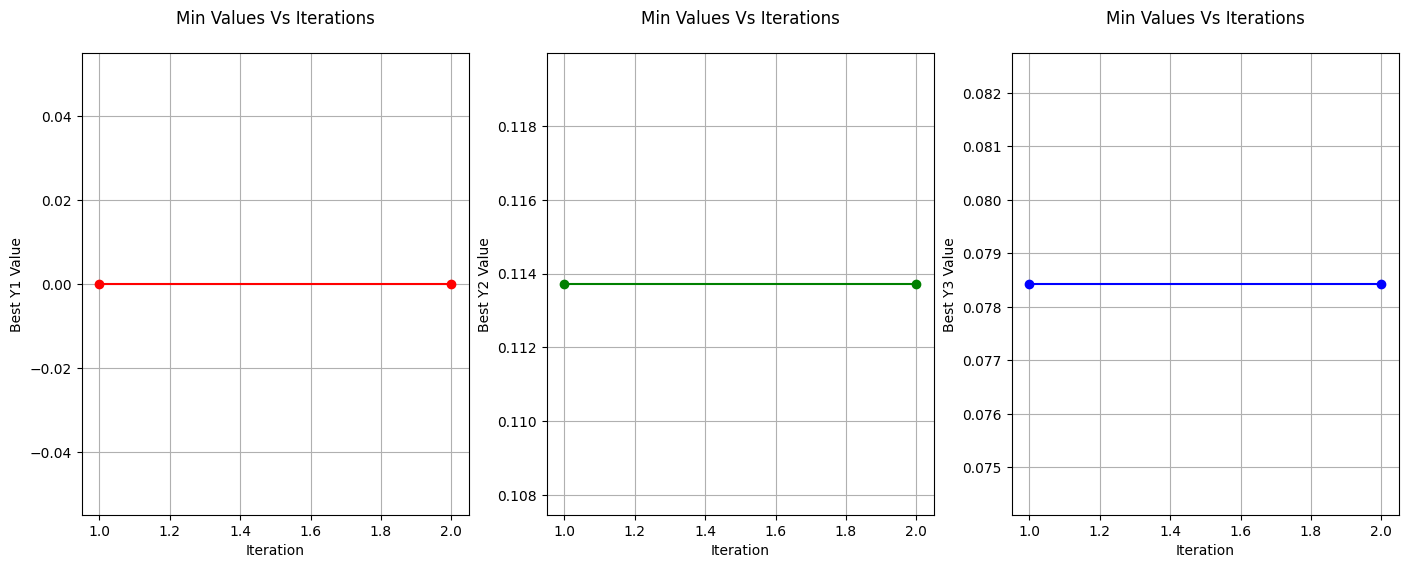

In [57]:
iterations = list(range(1, iteration_number+1))
plt.figure(figsize=(17, 6))
color = ['r','g','b']
for i in range(3):
    plt.subplot(1,3,i+1)
    plt.plot(iterations,best_y_values[:,i] , marker='o', linestyle='-', color=color[i] )
    # plt.plot(iterations,best_y_values[1] , marker='o', linestyle='-', color='r')
    # plt.plot(iterations,best_y_values[2] , marker='o', linestyle='-', color='g')
#plt.errorbar(iterations, np.mean(supra_best,axis=0),yerr=np.std(supra_best,axis=0))
    plt.title('Min Values Vs Iterations\n')
    plt.xlabel('Iteration')
    plt.ylabel('Best Y%s Value'%(i+1))
    plt.grid(True)
plt.show()


In [58]:
means = np.mean(means,axis=1)
# means = means.reshape(means.shape[0]*means.shape[1],means.shape[2])
variances = np.mean(variances,axis=1)
# variances = variances.reshape(variances.shape[0]*variances.shape[1],variances.shape[2])

In [65]:
means,variances

(array([[0.10065991, 0.19831146, 0.18691541],
        [0.18711938, 0.30979726, 0.27872112]], dtype=float32),
 array([[0.01588152, 0.01092465, 0.00820657],
        [0.18853736, 0.18643989, 0.18161567]], dtype=float32))

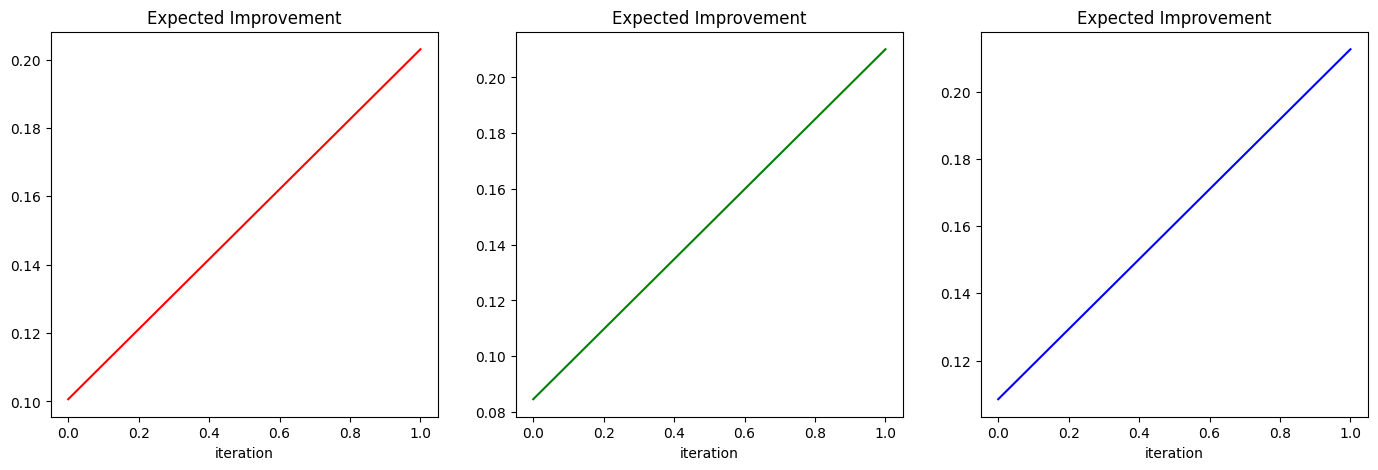

In [59]:
from scipy.stats import norm

def expected_improvement(mu, sigma, y_best, xi=0.01):
    z = (mu - y_best - xi) / sigma
    return (mu - y_best - xi) * norm.cdf(z) + sigma * norm.pdf(z)

plt.figure(figsize=(17, 5))
color = ['r','g','b']
for i in range(3):
    plt.subplot(1,3,i+1)
    plt.plot(expected_improvement(means,variances,best_y_values,xi=0)[:,i],color = color[i])
    plt.title("Expected Improvement")
    plt.xlabel("iteration")


In [66]:
expected_improvement(means,variances,best_y_values,xi=0)

array([[0.10065991, 0.08458597, 0.10848404],
       [0.20305372, 0.21013612, 0.21268276]])

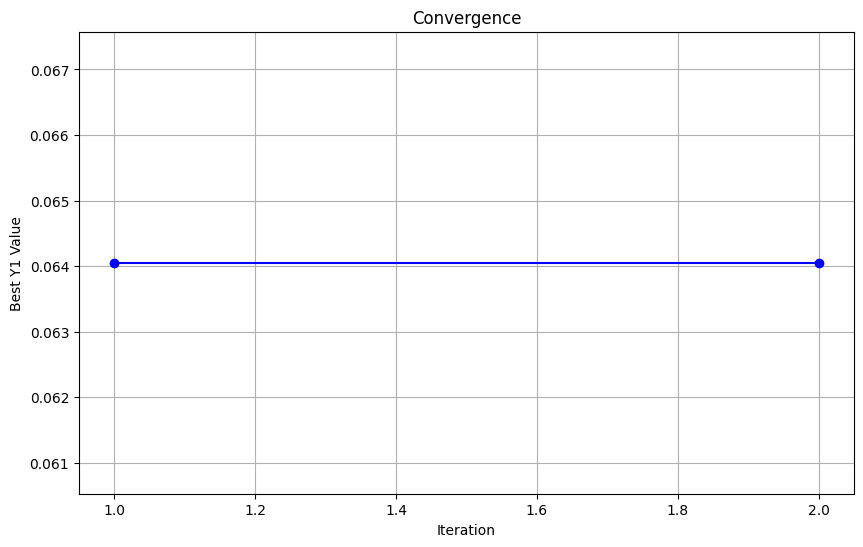

In [60]:
# Plotting convergence?
plt.figure(figsize=(10, 6))
plt.plot(iterations, np.mean(best_y_values,axis=1), marker='o', linestyle='-', color='b')
#plt.errorbar(iterations, np.mean(best_y_values,axis=1),yerr=np.std(supra_best,axis=1))
plt.title('Convergence')
plt.xlabel('Iteration')
plt.ylabel('Best Y1 Value')
plt.grid(True)
plt.show()

    

In [61]:
#frames_x[0][:, 1],frames_x[1][:, 1]#, frames_y

In [62]:
#train_x[len(frames_x[0]):len(train_x), 0], train_y[len(frames_x[0]):len(train_x)]

how do you use botroch SingleTaskGP to predict?